# Matching and retrieval with the selected descriptor

Qualitative figures for the slide that explains `inliers_by_query()` and `retrieve_with_unknowns()` (`utils.py`).
Everything uses the configuration of `main.PARAMS` (RootSIFT on Hessian-Laplace keypoints, gray, no CLAHE).

How two paintings are compared (`count_inliers`):

1. **Brute force kNN** (`BFMatcher.knnMatch(k=2)`): every query descriptor is compared (L2) with **all** the descriptors of the database image and its 2 nearest neighbours are kept.
2. **Lowe's ratio test**: the match is kept only if $d_1 < 0.75 \cdot d_2$, i.e. the nearest neighbour is clearly better than the second one (the point is distinctive, not ambiguous).
3. **RANSAC homography**: of the surviving matches, only those consistent with one homography (reprojection error < 5 px) are counted → **inliers**.

`inliers_by_query()` fills the matrix *inliers[painting, database image]*, and `retrieve_with_unknowns()` ranks each row: top-k IDs, or `[-1]` if the best one has fewer than `min_inliers` inliers.

## Setup

In [1]:
import sys
from pathlib import Path

# The notebook can be run from w4/ or from w4/visualizations/
W4_DIR = Path.cwd() if (Path.cwd() / "main.py").exists() else Path.cwd().parent
sys.path.insert(0, str(W4_DIR))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch, Rectangle

from main import PARAMS, BBDD_DIR, QUERY_DIR, GROUND_TRUTH_PATH
from descriptors import describe, NORMS
from keypoints import detect
from denoising import denoise_image
from segmentation import detect_paintings
from utils import resize_max_side, crop_to_mask, to_gray, load_pickle, load_images, count_inliers, \
    inliers_by_query, retrieve_with_unknowns, UNKNOWN

PARAMS

{'descriptor': 'rootsift',
 'detector': 'hessian_laplace',
 'color': 'gray',
 'clahe': False,
 'max_keypoints': 1000,
 'max_side': 800,
 'lowe_ratio': 0.75,
 'ransac_reproj_px': 5.0,
 'min_inliers': 40,
 'k': 10}

## Parameters

In [2]:
QUERY_ID = 1          # qsd1_w4 image (00001.jpg -> painting 150)
PAINTING = 0          # which painting of the query (if it has two)
WRONG_DB_ID = 48      # a database image that is NOT the right one, for comparison

# Figure 3, rejected example: the same query against a DIFFERENT painting, where the two nearest
# neighbours are at almost the same distance (no point of that painting is really the same one)
REJECT_DB_ID = WRONG_DB_ID
REJECT_POINT = None                      # query keypoint; None = choose automatically

LOWE = PARAMS["lowe_ratio"]
RANSAC_PX = PARAMS["ransac_reproj_px"]
GREEN, RED, ORANGE, BLUE = "#2ca02c", "#d62728", "#ff7f0e", "#1f77b4"

## Features exactly as in the pipeline

`features()` mirrors `describe()` but also returns the `cv2.KeyPoint`s (needed to draw the scale/orientation of the patches).
The `assert` checks that the points and descriptors are identical to the ones of `describe()`.

In [3]:
def features(image):
    # Same steps as describe(): detector keypoints -> SIFT compute -> RootSIFT
    gray = to_gray(image, PARAMS["clahe"])
    kps = detect(image, PARAMS["detector"], max_kps=PARAMS["max_keypoints"], clahe=PARAMS["clahe"])
    kps, d = cv2.SIFT_create().compute(gray, kps)
    d = np.sqrt(d / (d.sum(1, keepdims=True) + 1e-7)).astype(np.float32)   # RootSIFT
    points = np.float32([k.pt for k in kps])

    ref_points, ref_d = describe(image, PARAMS["descriptor"], PARAMS["detector"], PARAMS["color"],
                                 PARAMS["clahe"], PARAMS["max_keypoints"])
    assert np.allclose(points, ref_points) and np.allclose(d, ref_d, atol=1e-6)
    return kps, points, d


def query_painting(query_id, painting=0):
    # denoise -> detect paintings -> crop -> resize (as run_pipeline)
    query = denoise_image(cv2.imread(str(QUERY_DIR / f"{query_id:05d}.jpg")))
    masks = detect_paintings(query)
    return resize_max_side(crop_to_mask(query, masks[painting]), PARAMS["max_side"])


def db_painting(db_id):
    return resize_max_side(cv2.imread(str(BBDD_DIR / f"bbdd_{db_id:05d}.jpg")), PARAMS["max_side"])


ground_truth = load_pickle(GROUND_TRUTH_PATH)
GT_DB_ID = ground_truth[QUERY_ID][PAINTING]
print(f"Query {QUERY_ID:05d}, painting {PAINTING} -> ground truth bbdd_{GT_DB_ID:05d}")

q_img, db_img = query_painting(QUERY_ID, PAINTING), db_painting(GT_DB_ID)
q_kps, q_pts, q_desc = features(q_img)
db_kps, db_pts, db_desc = features(db_img)
print(f"Query: {len(q_kps)} keypoints  |  Database: {len(db_kps)} keypoints  |  D = {q_desc.shape[1]}")

Query 00001, painting 0 -> ground truth bbdd_00150


Query: 1334 keypoints  |  Database: 1425 keypoints  |  D = 128


## Matching step by step (what `count_inliers` does)

All the distances are computed once (`dist[i, j]` = L2 between query descriptor *i* and database descriptor *j*);
`BFMatcher.knnMatch(k=2)` returns exactly the two smallest values of each row.

In [4]:
def match_details(q_desc, q_pts, db_desc, db_pts):
    dist = np.linalg.norm(q_desc[:, None] - db_desc[None], axis=2)      # (n_query, n_db)
    nn = np.argsort(dist, axis=1)[:, :2]                                 # 1st and 2nd nearest neighbour
    d1, d2 = np.take_along_axis(dist, nn, 1).T
    ratio = d1 / d2
    lowe = ratio < LOWE

    inlier = np.zeros(len(q_desc), bool)
    if lowe.sum() >= 4:
        _, mask = cv2.findHomography(q_pts[lowe], db_pts[nn[lowe, 0]], cv2.RANSAC, RANSAC_PX)
        if mask is not None:
            inlier[np.flatnonzero(lowe)] = mask.ravel().astype(bool)
    return dict(dist=dist, nn=nn, d1=d1, d2=d2, ratio=ratio, lowe=lowe, inlier=inlier)


m = match_details(q_desc, q_pts, db_desc, db_pts)

# Sanity check against OpenCV's matcher (same nearest neighbours as knnMatch)
knn = cv2.BFMatcher(NORMS[PARAMS["descriptor"]]).knnMatch(q_desc, db_desc, k=2)
assert np.mean([p[0].trainIdx == m["nn"][i, 0] for i, p in enumerate(knn)]) > 0.99

print(f"Candidate pairs (all vs all): {m['dist'].size:,} distances")
print(f"After Lowe's ratio test:      {m['lowe'].sum()} matches")
print(f"RANSAC inliers:               {m['inlier'].sum()}  (count_inliers = "
      f"{count_inliers((q_pts, q_desc), (db_pts, db_desc), NORMS[PARAMS['descriptor']], LOWE, RANSAC_PX)})")

Candidate pairs (all vs all): 1,900,950 distances
After Lowe's ratio test:      225 matches
RANSAC inliers:               143  (count_inliers = 143)


Example points chosen automatically: a **distinctive** point (low ratio, RANSAC inlier) and an **ambiguous** one
(ratio close to 1: the two nearest neighbours are almost equally similar, so it is discarded).

In [5]:
good = np.flatnonzero(m["inlier"])
GOOD_PT = good[np.argmin(m["ratio"][good])] if len(good) else int(np.argmin(m["ratio"]))
# NN1 and NN2 far apart: not the same location duplicated by a second orientation
nn_gap = np.linalg.norm(db_pts[m["nn"][:, 0]] - db_pts[m["nn"][:, 1]], axis=1)
ambiguous = np.flatnonzero((m["ratio"] > 0.9) & (m["ratio"] < 0.99) & (nn_gap > 60))
BAD_PT = ambiguous[np.argmin(m["d1"][ambiguous])] if len(ambiguous) else int(np.argmax(m["ratio"]))

for name, i in [("distinctive", GOOD_PT), ("ambiguous", BAD_PT)]:
    print(f"{name:12s} point {i:4d}: d1 = {m['d1'][i]:.3f}  d2 = {m['d2'][i]:.3f}  ratio = {m['ratio'][i]:.2f}")

distinctive  point 1097: d1 = 0.148  d2 = 0.481  ratio = 0.31
ambiguous    point  236: d1 = 0.100  d2 = 0.103  ratio = 0.96


## Figure 1 — one query point against all the points of the database image

Lines from one query keypoint to **every** keypoint of the database image, coloured by descriptor distance
(dark = similar). The right panel shows all these distances sorted: only the two smallest ($d_1$, $d_2$) matter for Lowe's test.

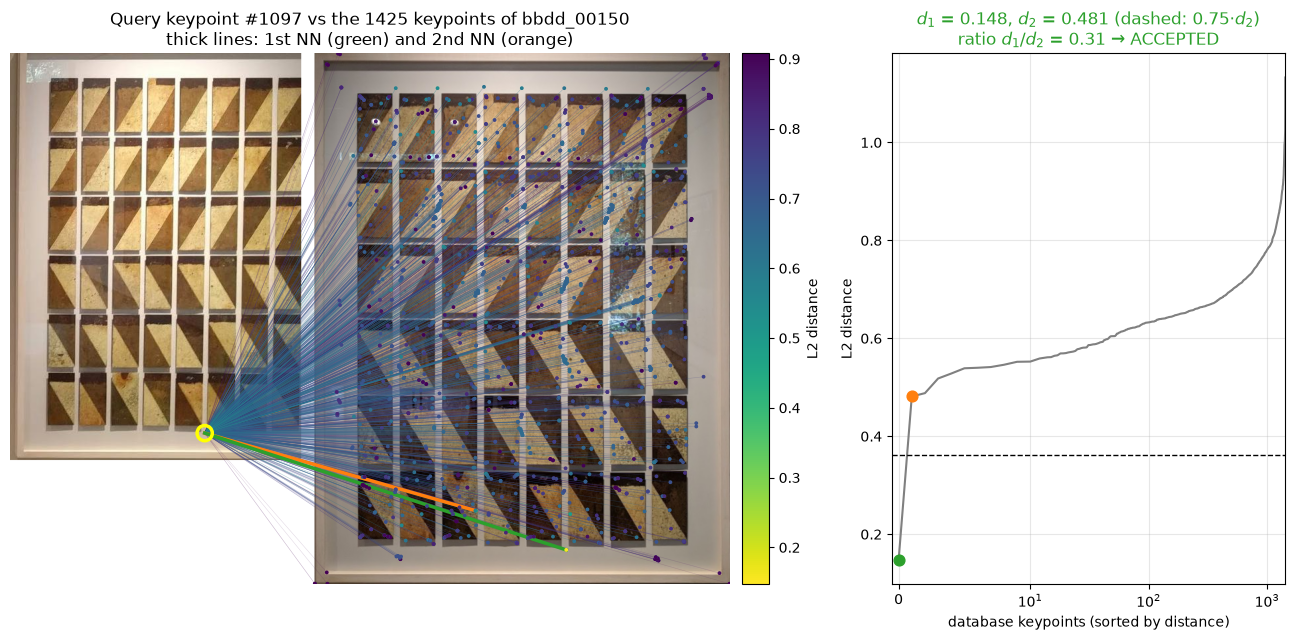

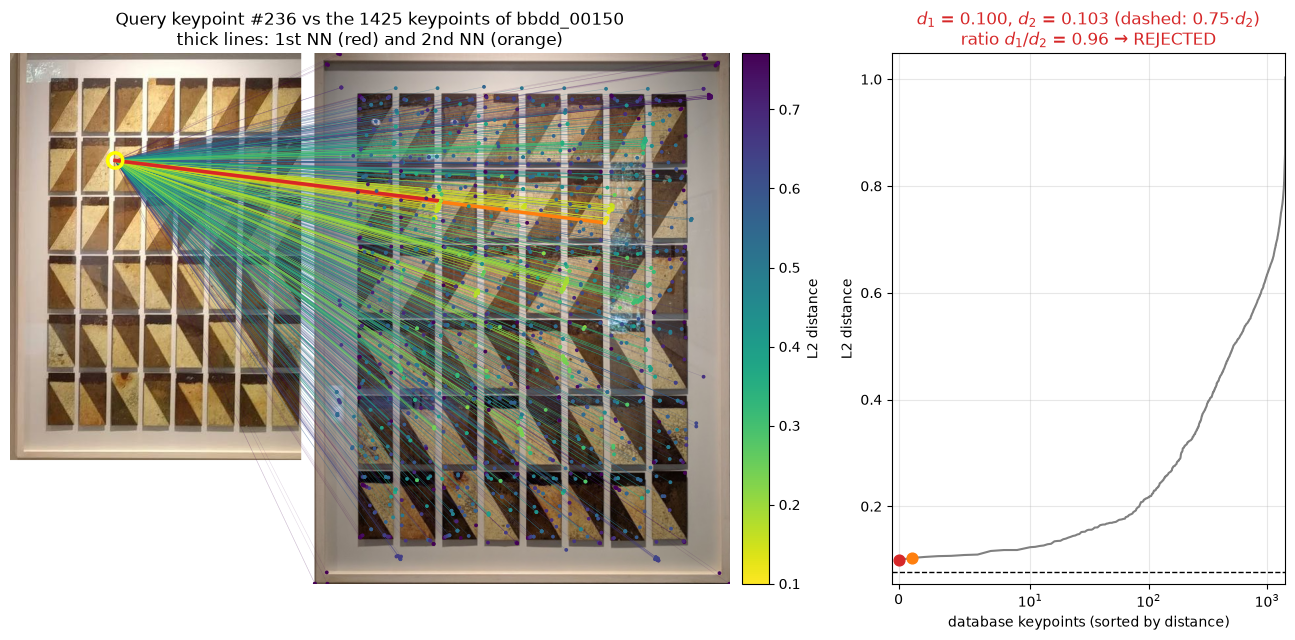

In [6]:
def side_by_side(a, b, gap=20):
    h = max(a.shape[0], b.shape[0])
    pad = lambda x: cv2.copyMakeBorder(x, 0, h - x.shape[0], 0, 0, cv2.BORDER_CONSTANT, value=(255, 255, 255))
    white = np.full((h, gap, 3), 255, np.uint8)
    return cv2.cvtColor(np.hstack([pad(a), white, pad(b)]), cv2.COLOR_BGR2RGB), a.shape[1] + gap


def plot_one_vs_all(i, ax_img, ax_curve, cmap="viridis_r"):
    canvas, off = side_by_side(q_img, db_img)
    ax_img.imshow(canvas)
    ax_img.axis("off")

    row = m["dist"][i]
    norm = plt.Normalize(row.min(), np.percentile(row, 95))
    p = q_pts[i]
    for j in np.argsort(-row):                                   # most similar drawn on top
        c = plt.get_cmap(cmap)(norm(row[j]))
        ax_img.plot([p[0], db_pts[j, 0] + off], [p[1], db_pts[j, 1]], color=c, lw=0.4,
                    alpha=0.15 + 0.5 * (1 - norm(row[j]).clip(0, 1)))
    n1, n2 = m["nn"][i]
    ok = m["ratio"][i] < LOWE
    ax_img.plot([p[0], db_pts[n2, 0] + off], [p[1], db_pts[n2, 1]], color=ORANGE, lw=2.5, label="2nd NN")
    ax_img.plot([p[0], db_pts[n1, 0] + off], [p[1], db_pts[n1, 1]], color=GREEN if ok else RED, lw=2.5,
                label="1st NN")
    ax_img.scatter(db_pts[:, 0] + off, db_pts[:, 1], s=3, c=plt.get_cmap(cmap)(norm(row)), zorder=3)
    ax_img.scatter(*p, s=120, facecolor="none", edgecolor="yellow", lw=2.5, zorder=4)
    ax_img.set_title(f"Query keypoint #{i} vs the {len(db_pts)} keypoints of bbdd_{GT_DB_ID:05d}\n"
                     f"thick lines: 1st NN ({'green' if ok else 'red'}) and 2nd NN (orange)")
    plt.colorbar(plt.cm.ScalarMappable(norm, cmap), ax=ax_img, fraction=0.025, pad=0.01, label="L2 distance")

    s = np.sort(row)
    ax_curve.plot(np.arange(len(s)), s, color="gray", lw=1.5)
    ax_curve.scatter([0], [s[0]], color=GREEN if ok else RED, s=60, zorder=3, label=f"$d_1$ = {s[0]:.3f}")
    ax_curve.scatter([1], [s[1]], color=ORANGE, s=60, zorder=3, label=f"$d_2$ = {s[1]:.3f}")
    ax_curve.axhline(LOWE * s[1], color="k", ls="--", lw=1, label=f"{LOWE} · $d_2$")
    ax_curve.set_xscale("symlog", linthresh=10)
    ax_curve.set_xlim(-0.5, len(s))
    ax_curve.set_xlabel("database keypoints (sorted by distance)")
    ax_curve.set_ylabel("L2 distance")
    verdict = "ACCEPTED" if ok else "REJECTED"
    ax_curve.set_title(f"$d_1$ = {s[0]:.3f}, $d_2$ = {s[1]:.3f} (dashed: {LOWE}·$d_2$)\n"
                       f"ratio $d_1/d_2$ = {m['ratio'][i]:.2f} → {verdict}", color=GREEN if ok else RED)
    ax_curve.grid(alpha=0.3)


for i in [GOOD_PT, BAD_PT]:
    fig, (a, b) = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw=dict(width_ratios=[3.2, 1]))
    plot_one_vs_all(i, a, b)
    plt.tight_layout()
    plt.show()

## Figure 2 — all query points against all database points (distance matrix)

Every row is a query keypoint, every column a database keypoint (subset for readability). `knnMatch` keeps
the 2 smallest values of each row (○ = 1st NN, × = 2nd NN); the row is a match only if the 1st one is clearly darker than the 2nd.

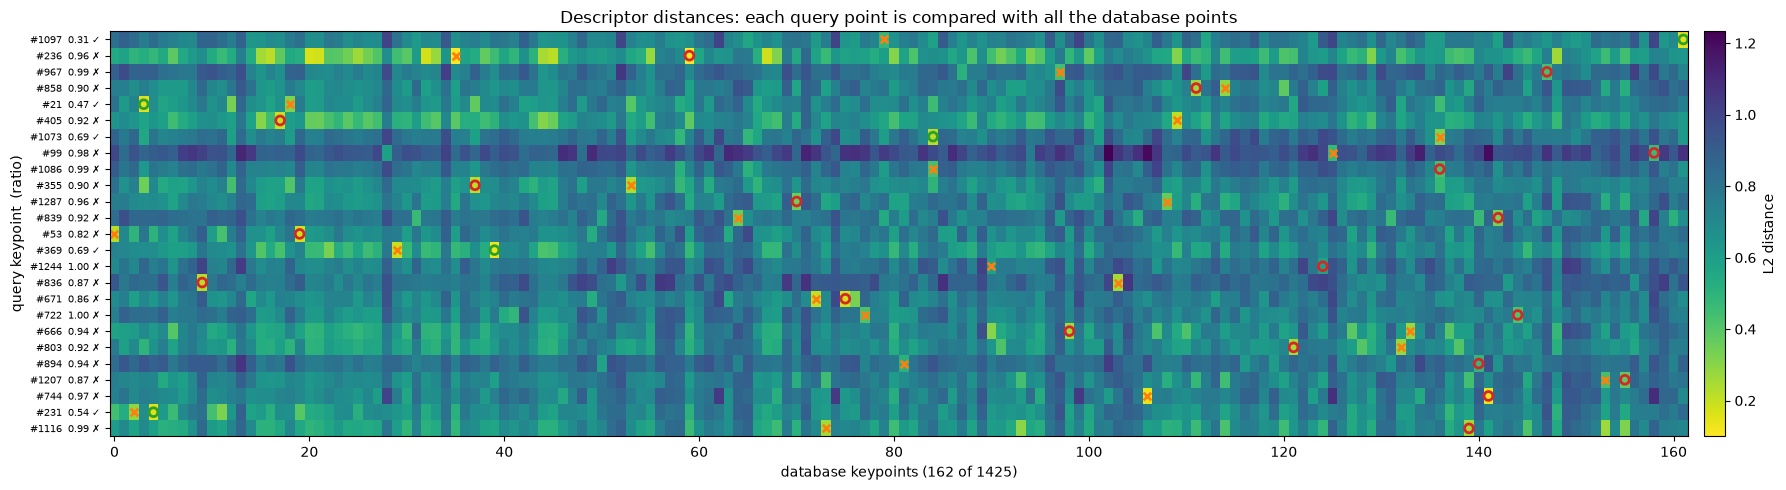

In [7]:
N_ROWS, N_COLS = 25, 120
rng = np.random.default_rng(0)
rows = np.r_[[GOOD_PT, BAD_PT], rng.choice(np.setdiff1d(np.arange(len(q_pts)), [GOOD_PT, BAD_PT]), N_ROWS - 2, replace=False)]
cols = np.unique(np.r_[m["nn"][rows].ravel(), rng.choice(len(db_pts), N_COLS, replace=False)])
sub = m["dist"][np.ix_(rows, cols)]

fig, ax = plt.subplots(figsize=(18, 5))
im = ax.imshow(sub, cmap="viridis_r", aspect="auto")
for r, i in enumerate(rows):
    c1, c2 = (np.searchsorted(cols, j) for j in m["nn"][i])
    ok = m["ratio"][i] < LOWE
    ax.scatter(c1, r, s=40, facecolor="none", edgecolor=GREEN if ok else RED, lw=2)
    ax.scatter(c2, r, s=30, marker="x", color=ORANGE, lw=2)
ax.set_yticks(range(len(rows)), [f"#{i}  {m['ratio'][i]:.2f}" + (" ✓" if m['ratio'][i] < LOWE else " ✗")
                                 for i in rows], fontsize=7)
ax.set_xlabel(f"database keypoints ({len(cols)} of {len(db_pts)})")
ax.set_ylabel("query keypoint  (ratio)")
ax.set_title("Descriptor distances: each query point is compared with all the database points")
plt.colorbar(im, ax=ax, fraction=0.02, pad=0.01, label="L2 distance")
plt.tight_layout()
plt.show()

## Figure 3 — zoom on the two nearest neighbours

What the descriptor "sees". Top row: zoom of the image around the query point and its 1st / 2nd nearest neighbours
(circle = descriptor support, line = orientation). Bottom row: the patch rotated to its orientation and scaled to its size
(that is why patches can be compared even if the painting is rotated or at another scale). Right: the 128-D RootSIFT descriptors.

Left: the two full paintings with the three points. All the squares have the same size; the figures are also saved in `figures/`.
Accepted example: query vs its own painting. Rejected example: the same query against a **different** painting (`REJECT_DB_ID`), where the 1st and 2nd neighbours are at almost the same distance.
The full paintings are always drawn in boxes of the same size, so both figures have the same layout.

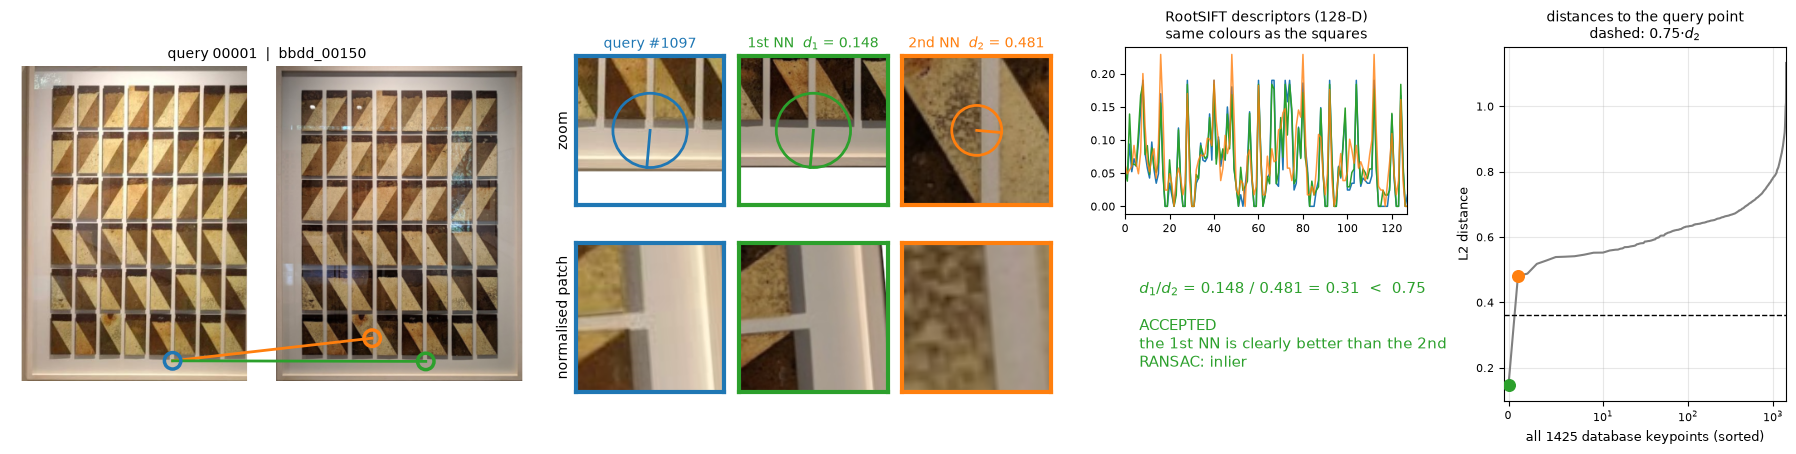

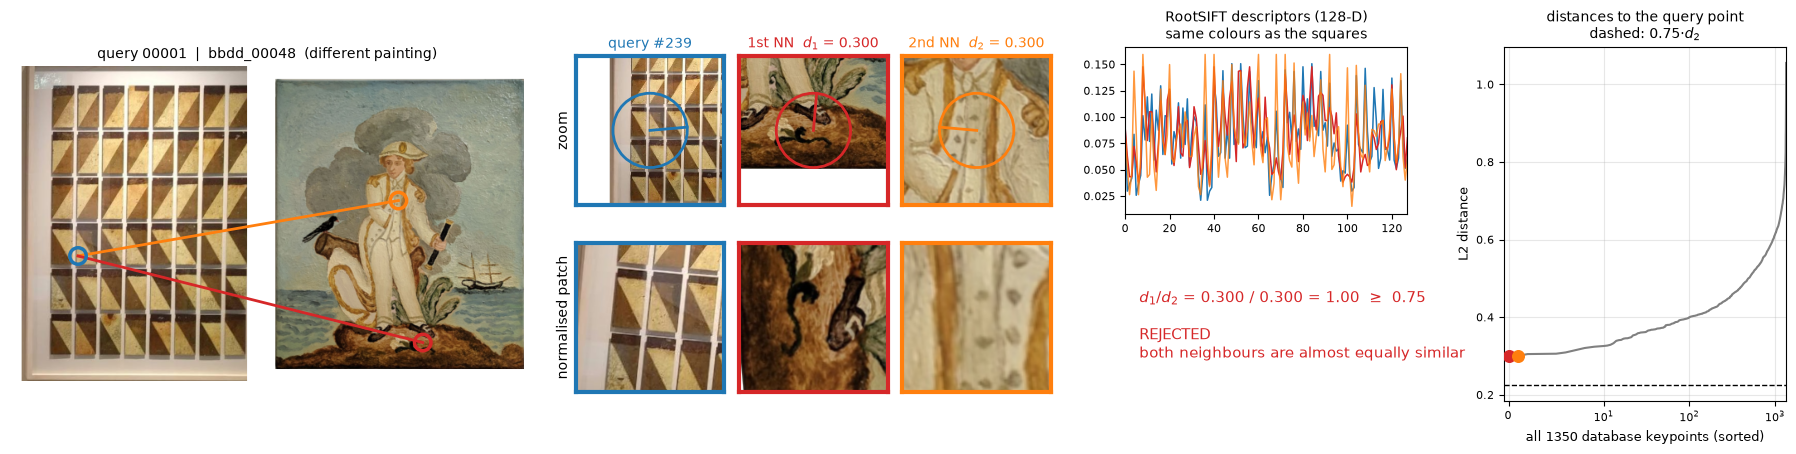

In [8]:
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SQ = 160          # side of every square (context zoom and patch), in pixels


def square_view(img, kp, half, rotate=False):
    # Square crop of side 2*half centred on the keypoint, resampled to SQ x SQ (rotated to the keypoint orientation if asked)
    M = cv2.getRotationMatrix2D(kp.pt, kp.angle if rotate else 0, SQ / (2 * half))
    M[:, 2] += SQ / 2 - np.array(kp.pt)
    out = cv2.warpAffine(img, M, (SQ, SQ), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT,
                         borderValue=(255, 255, 255))
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)


def show_square(ax, image, color, title=None):
    ax.imshow(image)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color(color); s.set_linewidth(3)
    if title:
        ax.set_title(title, fontsize=10, color=color)


BOX_W, BOX_H, BOX_GAP = 300, 380, 20      # every full painting is fitted into a box of this size (px)


def fit_box(img):
    # Resize to fit BOX_W x BOX_H (keeping the aspect ratio) and centre it on a white box
    s = min(BOX_W / img.shape[1], BOX_H / img.shape[0])
    im = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    ox, oy = (BOX_W - im.shape[1]) // 2, (BOX_H - im.shape[0]) // 2
    box = np.full((BOX_H, BOX_W, 3), 255, np.uint8)
    box[oy:oy + im.shape[0], ox:ox + im.shape[1]] = im
    return box, s, np.array([ox, oy], float)


def make_pair(query_id, painting, db_id=None):
    # Everything needed to plot one query painting against a database image (ground truth by default)
    db_id = ground_truth[query_id][painting] if db_id is None else db_id
    qi, di = query_painting(query_id, painting), db_painting(db_id)
    qk, qp, qd = features(qi)
    dk, dp, dd = features(di)
    return dict(query_id=query_id, db_id=db_id, q_img=qi, db_img=di, q_kps=qk, q_pts=qp, q_desc=qd,
                db_kps=dk, db_pts=dp, db_desc=dd, m=match_details(qd, qp, dd, dp))


def plot_neighbours(P, i, name):
    m = P["m"]
    n1, n2 = m["nn"][i]
    ok = m["ratio"][i] < LOWE
    c1 = GREEN if ok else RED
    items = [(P["q_img"], P["q_kps"][i], BLUE, f"query #{i}"),
             (P["db_img"], P["db_kps"][n1], c1, f"1st NN  $d_1$ = {m['d1'][i]:.3f}"),
             (P["db_img"], P["db_kps"][n2], ORANGE, f"2nd NN  $d_2$ = {m['d2'][i]:.3f}")]

    (qb, qs, qo), (db, ds, do) = fit_box(P["q_img"]), fit_box(P["db_img"])
    canvas = cv2.cvtColor(np.hstack([qb, np.full((BOX_H, BOX_GAP, 3), 255, np.uint8), db]), cv2.COLOR_BGR2RGB)
    do = do + [BOX_W + BOX_GAP, 0]
    full_w = 2.12 * canvas.shape[1] / canvas.shape[0]       # full-paintings panel, 2 squares high (in square units)
    ratios = [full_w, 0.15, 1, 1, 1, 0.3, 1.9, 0.45, 1.9]
    fig = plt.figure(figsize=(2.0 * sum(ratios) + 0.6, 4.6))
    gs = fig.add_gridspec(2, 9, width_ratios=ratios, wspace=0.08, hspace=0.12)

    # Full paintings with the three points
    ax = fig.add_subplot(gs[:, 0])
    ax.imshow(canvas)
    p, q1, q2 = P["q_pts"][i] * qs + qo, P["db_pts"][n1] * ds + do, P["db_pts"][n2] * ds + do
    ax.plot([p[0], q2[0]], [p[1], q2[1]], color=ORANGE, lw=2)
    ax.plot([p[0], q1[0]], [p[1], q1[1]], color=c1, lw=2)
    for (x, y), c in [(p, BLUE), (q1, c1), (q2, ORANGE)]:
        ax.scatter(x, y, s=140, facecolor="none", edgecolor=c, lw=2.5, zorder=3)
    same = P["db_id"] in ground_truth[P["query_id"]]
    ax.set_title(f"query {P['query_id']:05d}  |  bbdd_{P['db_id']:05d}" + ("" if same else "  (different painting)"),
                 fontsize=10)
    ax.axis("off")

    # Zooms (row 0) and normalised patches (row 1), all squares of the same size
    for col, (img, kp, c, title) in enumerate(items):
        half = max(40, 6 * kp.size)                      # context: a bit more than the descriptor support
        ax = fig.add_subplot(gs[0, 2 + col])
        show_square(ax, square_view(img, kp, half), c, title)
        r, a = 3 * kp.size * SQ / (2 * half), np.deg2rad(kp.angle)
        ax.add_patch(plt.Circle((SQ / 2, SQ / 2), r, fill=False, color=c, lw=2))
        ax.plot([SQ / 2, SQ / 2 + r * np.cos(a)], [SQ / 2, SQ / 2 + r * np.sin(a)], color=c, lw=2)
        ax.set_xlim(0, SQ); ax.set_ylim(SQ, 0)
        if col == 0:
            ax.set_ylabel("zoom", fontsize=10)
        ax2 = fig.add_subplot(gs[1, 2 + col])
        show_square(ax2, square_view(img, kp, 3 * kp.size, rotate=True), c)
        if col == 0:
            ax2.set_ylabel("normalised patch", fontsize=10)

    # Descriptors and verdict
    ax = fig.add_subplot(gs[0, 6])
    ax.plot(P["q_desc"][i], color=BLUE, lw=1.1, label="query")
    ax.plot(P["db_desc"][n1], color=c1, lw=1.1, label="1st NN")
    ax.plot(P["db_desc"][n2], color=ORANGE, lw=1.1, alpha=0.8, label="2nd NN")
    ax.set_title("RootSIFT descriptors (128-D)\nsame colours as the squares", fontsize=10)
    ax.set_xlim(0, 127); ax.tick_params(labelsize=8)

    ax = fig.add_subplot(gs[1, 6])
    ax.axis("off")
    verdict = "ACCEPTED\nthe 1st NN is clearly better than the 2nd" if ok else \
              "REJECTED\nboth neighbours are almost equally similar"
    if ok:
        verdict += "\nRANSAC: " + ("inlier" if m["inlier"][i] else "outlier")
    ax.text(0.05, 0.45, f"$d_1 / d_2$ = {m['d1'][i]:.3f} / {m['d2'][i]:.3f} = {m['ratio'][i]:.2f}"
                        f"  {'<' if ok else '≥'}  {LOWE}\n\n{verdict}",
            fontsize=11, va="center", color=c1)

    # Distances from the query point to all the database keypoints (sorted): d1, d2 and the Lowe threshold
    ax = fig.add_subplot(gs[:, 8])
    s = np.sort(m["dist"][i])
    ax.plot(np.arange(len(s)), s, color="gray", lw=1.5)
    ax.axhline(LOWE * s[1], color="k", ls="--", lw=1)
    ax.scatter([0], [s[0]], color=c1, s=70, zorder=3)
    ax.scatter([1], [s[1]], color=ORANGE, s=70, zorder=3)
    ax.set_xscale("symlog", linthresh=10)
    ax.set_xlim(-0.5, len(s))
    ax.set_xlabel(f"all {len(s)} database keypoints (sorted)", fontsize=9)
    ax.set_ylabel("L2 distance", fontsize=9)
    ax.set_title(f"distances to the query point\ndashed: {LOWE}·$d_2$", fontsize=10)
    ax.tick_params(labelsize=8)
    ax.grid(alpha=0.3)

    fig.savefig(FIG_DIR / f"neighbours_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


main_pair = dict(query_id=QUERY_ID, db_id=GT_DB_ID, q_img=q_img, db_img=db_img, q_kps=q_kps, q_pts=q_pts,
                 q_desc=q_desc, db_kps=db_kps, db_pts=db_pts, db_desc=db_desc, m=m)
plot_neighbours(main_pair, GOOD_PT, "accepted")

reject_pair = make_pair(QUERY_ID, PAINTING, db_id=REJECT_DB_ID)
rm = reject_pair["m"]
if REJECT_POINT is None:
    # ratio close to 1 and the two neighbours at different places (not one point duplicated by orientation)
    gap = np.linalg.norm(reject_pair["db_pts"][rm["nn"][:, 0]] - reject_pair["db_pts"][rm["nn"][:, 1]], axis=1)
    cand = np.flatnonzero((rm["ratio"] > 0.95) & (gap > 60))
    REJECT_POINT = int(cand[np.argmin(rm["d1"][cand])])
plot_neighbours(reject_pair, REJECT_POINT, "rejected")

## Figure 3b — RANSAC homography

How `cv2.findHomography(..., cv2.RANSAC, 5)` turns the Lowe matches into an inlier count:

1. **Sample**: pick 4 random matches and compute the homography $H$ (query → database) that maps them exactly.
2. **Consensus**: a match $(p, q)$ agrees with $H$ (inlier) if the reprojection error $\lVert Hp - q \rVert < 5$ px.
   Repeat 1–2 many times and keep the sample with most inliers; finally $H$ is refitted with all its inliers.
3. **Result**: where $H$ puts every query point on the database painting ($Hp$), with the 4 sample points numbered.

The RANSAC loop is re-implemented here (seed fixed) only to know **which 4 matches** were sampled; the final inliers are
the same kind of count that `count_inliers` stores. All the paintings are drawn in boxes of the same size.

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7024\1873538337.py:10: RuntimeWarning: divide by zero encountered in divide
  err = np.linalg.norm(proj[:, :2] / proj[:, 2:3] - dst, axis=1)
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_7024\1873538337.py:10: RuntimeWarning: invalid value encountered in divide
  err = np.linalg.norm(proj[:, :2] / proj[:, 2:3] - dst, axis=1)


best sample: 144 inliers  ->  refitted H: 143 inliers  (count_inliers: 143)
sample shown: 136 inliers


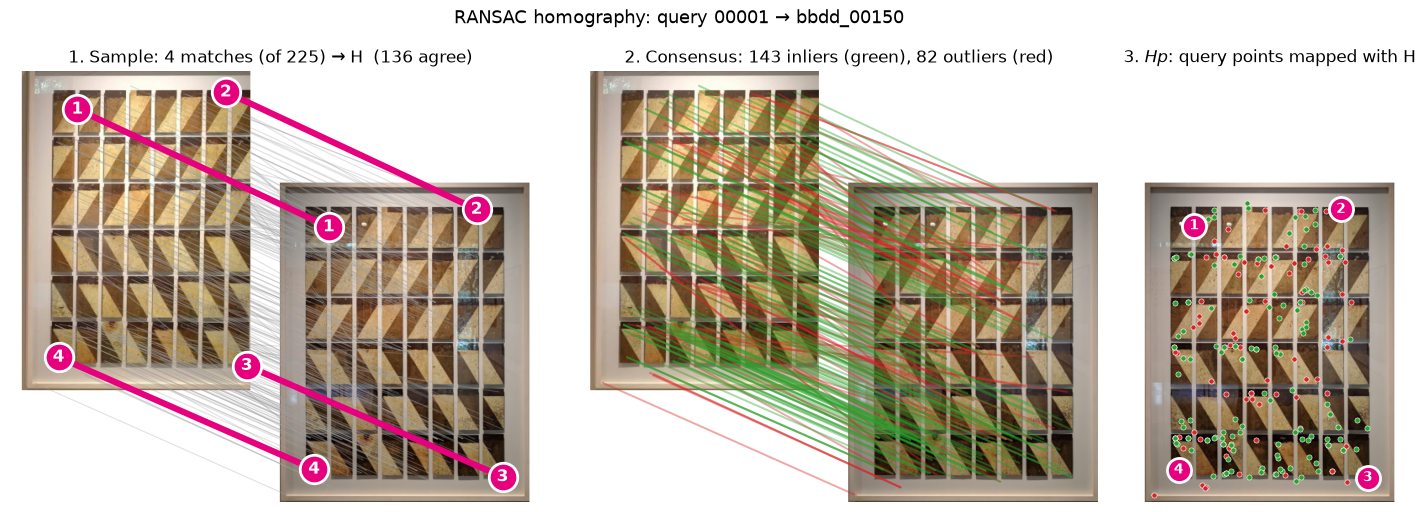

In [9]:
def ransac_best_sample(src, dst, iters=2000, seed=0):
    # Plain RANSAC: 4 random matches -> exact H -> count matches with reprojection error < RANSAC_PX
    rng = np.random.default_rng(seed)
    src_h = np.hstack([src, np.ones((len(src), 1), np.float32)])
    best_n, best_idx = -1, None
    for _ in range(iters):
        idx = rng.choice(len(src), 4, replace=False)
        H = cv2.getPerspectiveTransform(src[idx], dst[idx])
        proj = src_h @ H.T
        err = np.linalg.norm(proj[:, :2] / proj[:, 2:3] - dst, axis=1)
        n = int((err < RANSAC_PX).sum())
        if n > best_n:
            best_n, best_idx = n, idx
    return best_idx, best_n


def reprojection(H, src, dst):
    proj = cv2.perspectiveTransform(src[None], H)[0]
    return proj, np.linalg.norm(proj - dst, axis=1)


DIAG = 0.35          # the database painting is shifted down by DIAG * BOX_H (diagonal layout)


def pair_in_boxes(q_img, db_img, diag=0.0):
    # Both paintings in boxes of the same size, the database one shifted down by diag * BOX_H
    (qb, qs, qo), (db, ds, do) = fit_box(q_img), fit_box(db_img)
    dy = int(diag * BOX_H)
    canvas = np.full((BOX_H + dy, 2 * BOX_W + BOX_GAP, 3), 255, np.uint8)
    canvas[:BOX_H, :BOX_W] = qb
    canvas[dy:dy + BOX_H, BOX_W + BOX_GAP:] = db
    canvas = cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)
    do = do + [BOX_W + BOX_GAP, dy]
    return canvas, (lambda p: p * qs + qo), (lambda p: p * ds + do)


def draw_numbered(ax, pts, s=420, fontsize=12):
    for k, (x, y) in enumerate(pts, start=1):
        ax.scatter(x, y, s=s, color="#e6007e", edgecolor="white", lw=2, zorder=4)
        ax.text(x, y, str(k), color="white", fontsize=fontsize, ha="center", va="center", weight="bold", zorder=5)


def plot_homography(db_id, name):
    img = db_img if db_id == GT_DB_ID else db_painting(db_id)
    pts, desc = (db_pts, db_desc) if db_id == GT_DB_ID else features(img)[1:]
    mm = m if db_id == GT_DB_ID else match_details(q_desc, q_pts, desc, pts)
    src, dst = q_pts[mm["lowe"]], pts[mm["nn"][mm["lowe"], 0]]

    # best 4-point sample -> its inliers -> H refitted on them (as OpenCV does) -> final consensus
    sample, n_sample = ransac_best_sample(src, dst)
    H0 = cv2.getPerspectiveTransform(src[sample], dst[sample])
    inl = reprojection(H0, src, dst)[1] < RANSAC_PX
    H = cv2.findHomography(src[inl], dst[inl], 0)[0]
    proj, err = reprojection(H, src, dst)
    inl = err < RANSAC_PX
    n_cv = count_inliers((q_pts, q_desc), (pts, desc), NORMS[PARAMS["descriptor"]], LOWE, RANSAC_PX)
    print(f"best sample: {n_sample} inliers  ->  refitted H: {inl.sum()} inliers  (count_inliers: {n_cv})")

    # Sample shown in the figure: 4 inliers well spread over the painting (the one closest to each corner),
    # so the 4 matches are easy to see. Any good sample gives (almost) the same consensus.
    h, w = q_img.shape[:2]
    cand = np.flatnonzero(inl)
    sample = []
    for corner in [(0, 0), (w, 0), (w, h), (0, h)]:
        d = np.linalg.norm(src[cand] - corner, axis=1)
        d[np.isin(cand, sample)] = np.inf
        sample.append(int(cand[np.argmin(d)]))
    sample = np.array(sample)
    n_shown = int((reprojection(cv2.getPerspectiveTransform(src[sample], dst[sample]), src, dst)[1] < RANSAC_PX).sum())
    print(f"sample shown: {n_shown} inliers")

    canvas, map_q, map_db = pair_in_boxes(q_img, img, DIAG)
    sq, sd = map_q(src), map_db(dst)
    dy = int(DIAG * BOX_H)

    fig = plt.figure(figsize=(18, 5.6))
    gs = fig.add_gridspec(1, 3, width_ratios=[canvas.shape[1], canvas.shape[1], BOX_W], wspace=0.08)

    # 1. The 4 sampled matches (numbered) among all the Lowe matches
    ax = fig.add_subplot(gs[0])
    ax.imshow(canvas)
    for (x0, y0), (x1, y1) in zip(sq, sd):
        ax.plot([x0, x1], [y0, y1], color="#9e9e9e", lw=0.8, alpha=0.3)
    for j in sample:
        ax.plot([sq[j, 0], sd[j, 0]], [sq[j, 1], sd[j, 1]], color="#e6007e", lw=4.5, solid_capstyle="round", zorder=3)
    draw_numbered(ax, sq[sample])
    draw_numbered(ax, sd[sample])
    ax.set_title(f"1. Sample: 4 matches (of {len(src)}) → H  ({n_shown} agree)", fontsize=12)
    ax.axis("off")

    # 2. Inliers / outliers of H
    ax = fig.add_subplot(gs[1])
    ax.imshow(canvas)
    for keep, c in [(~inl, RED), (inl, GREEN)]:
        for (x0, y0), (x1, y1) in zip(sq[keep], sd[keep]):
            ax.plot([x0, x1], [y0, y1], color=c, lw=1.4, alpha=0.4)
    ax.set_title(f"2. Consensus: {inl.sum()} inliers (green), {(~inl).sum()} outliers (red)", fontsize=12)
    ax.axis("off")

    # 3. Where H puts the query points on the database painting (same position as in panels 1-2)
    ax = fig.add_subplot(gs[2])
    box, s, o = fit_box(img)
    panel = np.full((BOX_H + dy, BOX_W, 3), 255, np.uint8)
    panel[dy:dy + BOX_H] = box
    o = o + [0, dy]
    ax.imshow(cv2.cvtColor(panel, cv2.COLOR_BGR2RGB))
    for keep, c in [(~inl, RED), (inl, GREEN)]:
        P0 = proj[keep] * s + o
        ax.scatter(P0[:, 0], P0[:, 1], s=14, color=c, edgecolor="white", lw=0.4, zorder=3)
    draw_numbered(ax, proj[sample] * s + o, s=300, fontsize=10)
    ax.set_title("3. $Hp$: query points mapped with H", fontsize=12)
    ax.axis("off")

    fig.suptitle(f"RANSAC homography: query {QUERY_ID:05d} → bbdd_{db_id:05d}", fontsize=13, y=0.99)
    fig.savefig(FIG_DIR / f"homography_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


plot_homography(GT_DB_ID, "correct")

## Figure 3c — what a homography does (simulated perspective)

In qsd1_w4 the paintings are photographed almost frontally and cropped, so the estimated $H$ is close to a scale + shift
and its perspective part is barely visible (max corner angle deviation over all the queries ≈ 4°).
To show what a homography is, the query is **re-photographed synthetically from an angle** (a known perspective warp)
and the same pipeline (RootSIFT → Lowe → RANSAC) estimates $H$ again:

1. A regular grid on the database painting, projected into the tilted photo with $H^{-1}$: straight lines stay straight,
   but parallel lines converge — that is a homography.
2. The tilted photo warped with $H$ (rectified): it becomes frontal again and fits the same regular grid.
3. The database painting with the regular grid.

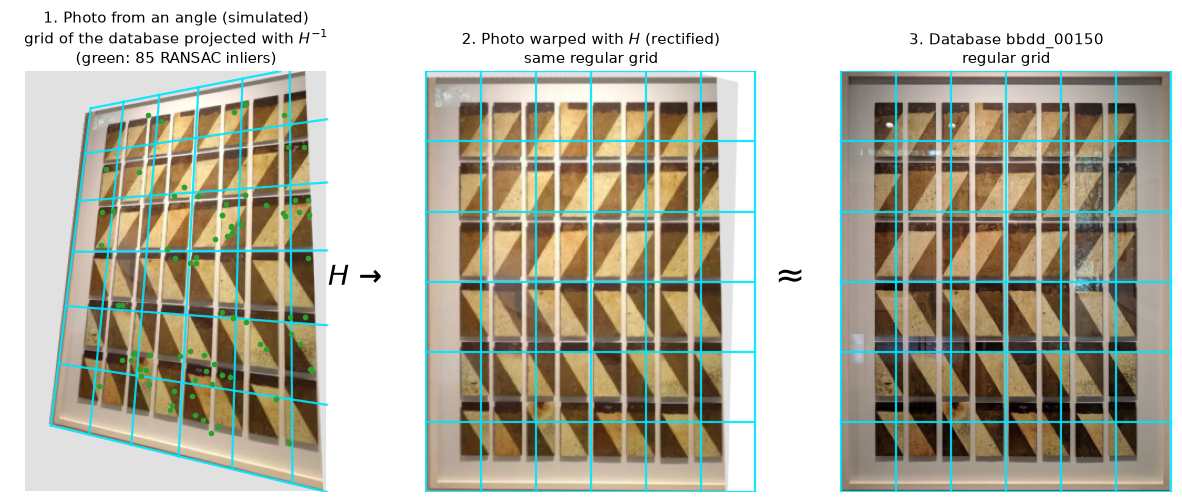

135 matches after Lowe, 85 inliers
H =
 [[ 2.672800e+00  3.315000e-01 -2.710362e+02]
 [ 4.825000e-01  2.458300e+00 -1.781148e+02]
 [ 1.200000e-03  7.000000e-04  1.000000e+00]]


In [10]:
def tilt(img, corners_frac, background=(225, 225, 225)):
    # Synthetic photo from an angle: the painting corners go to corners_frac * (w, h)
    h, w = img.shape[:2]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    dst = np.float32(np.float32(corners_frac) * [w, h])
    T = cv2.getPerspectiveTransform(src, dst)
    return cv2.warpPerspective(img, T, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=background)


TILT = [(0.20, 0.10), (0.93, 0.00), (0.99, 1.00), (0.08, 0.84)]   # TL, TR, BR, BL
N_GRID = 6
GRID_COLOR = "#00e5ff"


def grid_lines(w, h, n=N_GRID):
    xs, ys = np.linspace(0, w, n + 1), np.linspace(0, h, n + 1)
    return [np.float32([[x, 0], [x, h]]) for x in xs] + [np.float32([[0, y], [w, y]]) for y in ys]


def draw_grid(ax, lines, M, s, o, img_shape, lw=1.6):
    # Grid lines (projected with M if given), clipped to the image area inside the box
    for line in lines:
        p = cv2.perspectiveTransform(line[None], M)[0] if M is not None else line
        ok, a, b = cv2.clipLine((0, 0, img_shape[1] + 1, img_shape[0] + 1),
                                tuple(int(round(v)) for v in p[0]), tuple(int(round(v)) for v in p[1]))
        if ok:
            p = np.float32([a, b]) * s + o
            ax.plot(p[:, 0], p[:, 1], color=GRID_COLOR, lw=lw, alpha=0.9)


def plot_perspective(db_id=GT_DB_ID):
    t_img = tilt(q_img, TILT)
    _, t_pts, t_desc = features(t_img)
    mt = match_details(t_desc, t_pts, db_desc, db_pts)
    src, dst = t_pts[mt["lowe"]], db_pts[mt["nn"][mt["lowe"], 0]]
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_PX)
    inl = mask.ravel().astype(bool)
    Hinv = np.linalg.inv(H)
    h, w = db_img.shape[:2]
    lines = grid_lines(w, h)
    rectified = cv2.warpPerspective(t_img, H, (w, h), borderValue=(255, 255, 255))

    fig, axes = plt.subplots(1, 3, figsize=(15, 6.6))
    panels = [(t_img, Hinv, f"1. Photo from an angle (simulated)\ngrid of the database projected with $H^{{-1}}$"),
              (rectified, None, "2. Photo warped with $H$ (rectified)\nsame regular grid"),
              (db_img, None, f"3. Database bbdd_{db_id:05d}\nregular grid")]
    for ax, (img, M, title) in zip(axes, panels):
        box, s, o = fit_box(img)
        ax.imshow(cv2.cvtColor(box, cv2.COLOR_BGR2RGB))
        draw_grid(ax, lines, M, s, o, img.shape)
        if M is not None:                                   # inlier matches on the tilted photo
            p = src[inl] * s + o
            ax.scatter(p[:, 0], p[:, 1], s=9, color=GREEN, zorder=3)
            title += f"\n(green: {inl.sum()} RANSAC inliers)"
        ax.set_xlim(0, BOX_W); ax.set_ylim(BOX_H, 0)
        ax.set_title(title, fontsize=11)
        ax.axis("off")

    fig.text(0.355, 0.5, "$H$ →", fontsize=20, ha="center", va="center", weight="bold")
    fig.text(0.645, 0.5, "≈", fontsize=26, ha="center", va="center")
    plt.subplots_adjust(wspace=0.25)
    fig.savefig(FIG_DIR / "homography_perspective.png", dpi=200, bbox_inches="tight")
    plt.show()
    print(f"{len(src)} matches after Lowe, {inl.sum()} inliers")
    print("H =\n", np.round(H, 4))


plot_perspective()

## Figure 4 — result of `count_inliers`: right vs wrong database image

Lines = matches that pass Lowe's test; <span style="color:green">green</span> = RANSAC inliers,
<span style="color:red">red</span> = outliers. The number of inliers is the value stored in the inlier matrix.

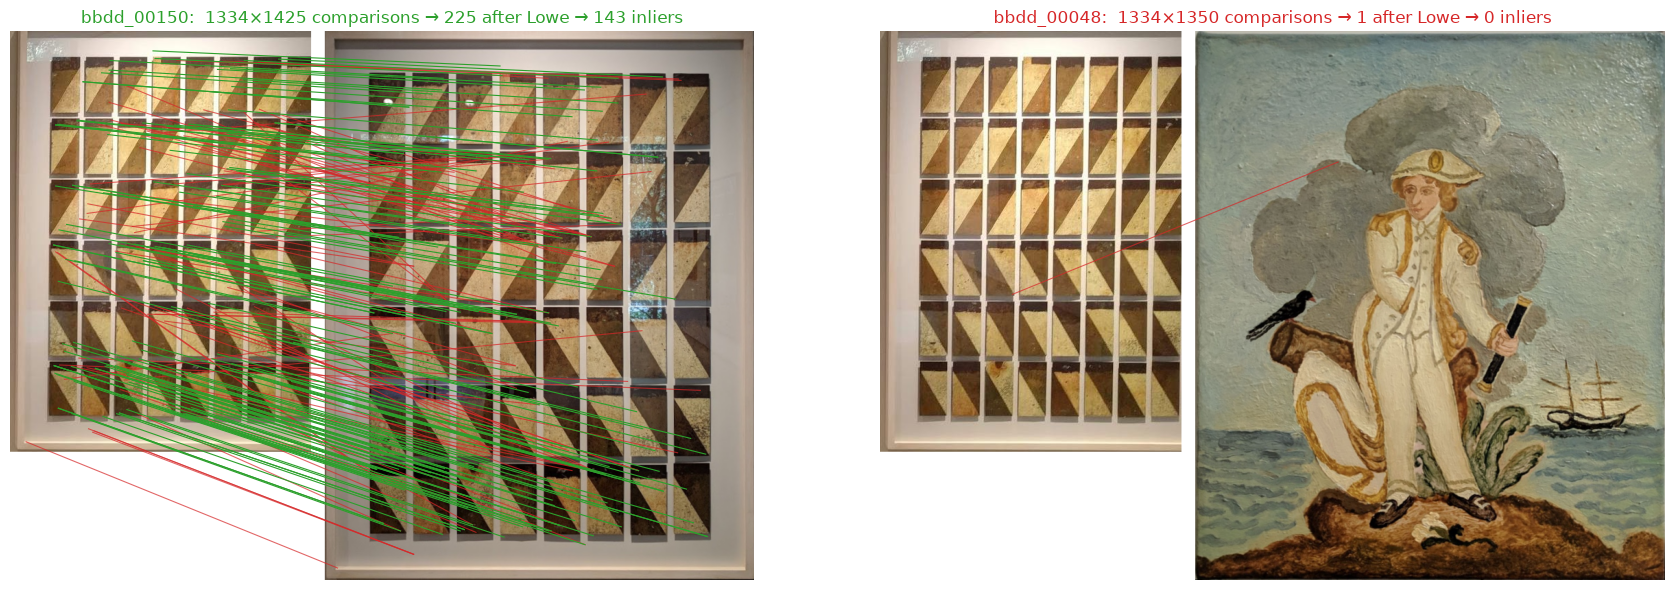

In [11]:
def plot_matches(ax, db_id):
    img = db_painting(db_id)
    _, pts, desc = features(img)
    mm = match_details(q_desc, q_pts, desc, pts)
    canvas, off = side_by_side(q_img, img)
    ax.imshow(canvas)
    for i in np.flatnonzero(mm["lowe"] & ~mm["inlier"]):
        j = mm["nn"][i, 0]
        ax.plot([q_pts[i, 0], pts[j, 0] + off], [q_pts[i, 1], pts[j, 1]], color=RED, lw=0.8, alpha=0.7)
    for i in np.flatnonzero(mm["inlier"]):
        j = mm["nn"][i, 0]
        ax.plot([q_pts[i, 0], pts[j, 0] + off], [q_pts[i, 1], pts[j, 1]], color=GREEN, lw=0.8)
    n_in = mm["inlier"].sum()
    ok = n_in >= PARAMS["min_inliers"]
    ax.set_title(f"bbdd_{db_id:05d}:  {len(q_pts)}×{len(pts)} comparisons → {mm['lowe'].sum()} after Lowe → "
                 f"{n_in} inliers", color=GREEN if ok else RED)
    ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(18, 6))
plot_matches(axes[0], GT_DB_ID)
plot_matches(axes[1], WRONG_DB_ID)
plt.tight_layout()
plt.show()

## Figure 5 — retrieval (`retrieve_with_unknowns`)

One row of the inlier matrix per painting: inliers against every database image. The database IDs are ranked by
inliers (top-k); if the best one is below `min_inliers` the painting is answered with `[-1]` (not in the database).

Describing the 287 database images takes a few minutes, so the inlier rows are cached in `matching_cache.pkl`.

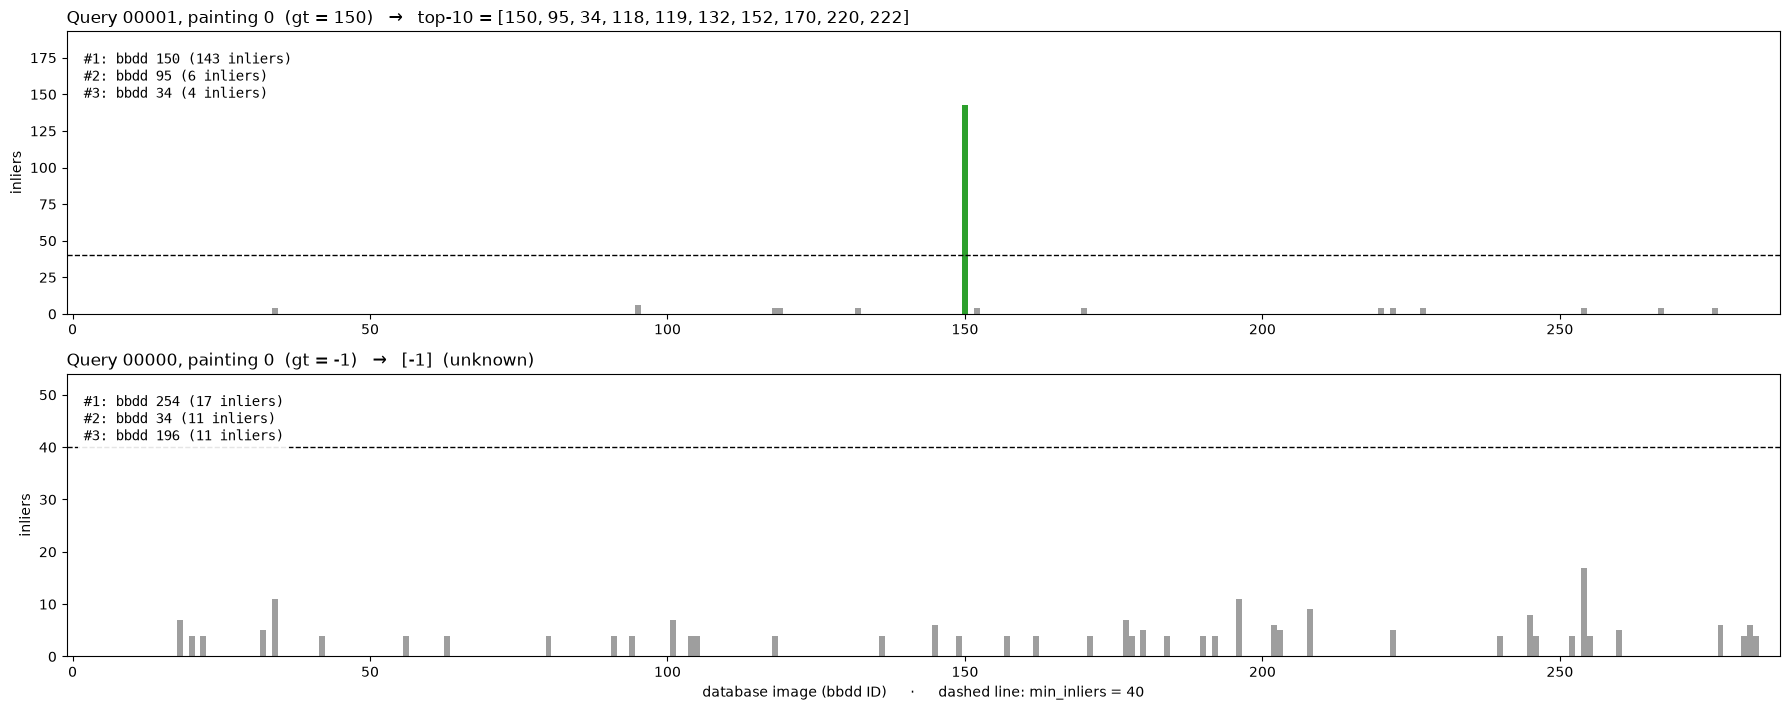

In [12]:
import pickle

EXAMPLES = [(QUERY_ID, PAINTING), (0, 0)]        # a known painting and an unknown one (gt = -1)
CACHE = Path("matching_cache.pkl")

if CACHE.exists():
    db_ids, rows = pickle.load(open(CACHE, "rb"))
else:
    db_ids, db_images = load_images(BBDD_DIR)
    db_features = [describe(resize_max_side(im, PARAMS["max_side"]), PARAMS["descriptor"], PARAMS["detector"],
                            PARAMS["color"], PARAMS["clahe"], PARAMS["max_keypoints"]) for im in db_images]
    query_features = [[features(query_painting(q, p))[1:]] for q, p in EXAMPLES]
    rows = inliers_by_query(query_features, db_features, NORMS[PARAMS["descriptor"]], LOWE, RANSAC_PX)
    pickle.dump((db_ids, rows), open(CACHE, "wb"))

predictions = retrieve_with_unknowns(rows, db_ids, PARAMS["k"], PARAMS["min_inliers"])

fig, axes = plt.subplots(len(EXAMPLES), 1, figsize=(18, 3.6 * len(EXAMPLES)))
for ax, (q, p), row, pred in zip(axes, EXAMPLES, rows, predictions):
    row = row[0]
    gt = ground_truth[q][p]
    colors = [GREEN if i == gt else "#9e9e9e" for i in db_ids]
    ax.bar(range(len(db_ids)), row, color=colors, width=1.0)
    ax.axhline(PARAMS["min_inliers"], color="k", ls="--", lw=1, label=f"min_inliers = {PARAMS['min_inliers']}")
    top = np.argsort(-row, kind="stable")[:3]
    ax.text(0.01, 0.93, "\n".join(f"#{r + 1}: bbdd {db_ids[j]} ({row[j]} inliers)" for r, j in enumerate(top)),
            transform=ax.transAxes, va="top", fontsize=10, family="monospace",
            bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
    ax.set_ylim(0, 1.35 *max(row.max(), PARAMS["min_inliers"]))
    answer = "[-1]  (unknown)" if pred[0] == [UNKNOWN] else f"top-{PARAMS['k']} = {pred[0]}"
    ax.set_title(f"Query {q:05d}, painting {p}  (gt = {gt})   →   {answer}", loc="left")
    ax.set_xlim(-1, len(db_ids))
    ax.set_ylabel("inliers")
axes[-1].set_xlabel(f"database image (bbdd ID)      ·      dashed line: min_inliers = {PARAMS['min_inliers']}")
plt.tight_layout()
plt.show()